## Model 2 : Remaining Useful Life (cycles) prediction

### Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import joblib

In [2]:
from sklearn.preprocessing import LabelEncoder,StandardScaler
from sklearn.model_selection import train_test_split

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Load dataset

In [5]:
df=pd.read_csv("../dataset/ev_battery_health.csv")

In [8]:
df.shape

(50000, 35)

In [6]:
df.head()

,battery_id,observation_id,chemistry,manufacturer,vehicle_model,pack_capacity_kwh,manufacture_date,observation_date,battery_age_days,cycle_count,...,peak_temp_during_fast_charge_c,capacity_fade_pct,service_count,last_service_date,bms_firmware_version,recall_flag,state_of_health_pct,remaining_useful_life_cycles,failure_risk_label,degradation_category
0,BATT_01748,OBS_033554,LMO,StormCell,Crossover-X2,48.5,2022-11-23,2024-10-16,693.0,991.0,...,-1.3,19.13,4.0,2023-12-25,BMS_v2.1,0.0,80.87,0,High,Normal
1,BATT_00491,OBS_009428,LFP,VoltaCore,Sedan-E1,61.5,2023-03-06,2024-12-27,662.0,1535.0,...,5.3,8.19,0.0,NaN,BMS_v3.2,0.0,91.81,1739,Low,Normal
2,BATT_00011,OBS_000200,LFP,IonFlux,Van-E4,73.1,2025-06-24,2026-02-10,NaN,407.0,...,21.3,2.52,0.0,NaN,NaN,0.0,97.48,3248,Low,Normal
3,BATT_00651,OBS_012448,NMC,Amperion,NaN,75.6,2022-08-13,2022-09-15,33.0,29.0,...,20.8,0.82,0.0,NaN,BMS_v3.5,0.0,99.18,1375,Low,Normal
4,BATT_02054,OBS_039490,NCA,VoltaCore,Hatch-E3,92.7,2024-09-27,2026-03-01,520.0,324.0,...,40.1,8.14,0.0,NaN,BMS_v2.1,0.0,91.86,715,Low,Normal


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 35 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   battery_id                      50000 non-null  object 
 1   observation_id                  50000 non-null  object 
 2   chemistry                       46541 non-null  object 
 3   manufacturer                    47539 non-null  object 
 4   vehicle_model                   46485 non-null  object 
 5   pack_capacity_kwh               47698 non-null  float64
 6   manufacture_date                48090 non-null  object 
 7   observation_date                47784 non-null  object 
 8   battery_age_days                46998 non-null  float64
 9   cycle_count                     47731 non-null  float64
 10  climate_zone                    47281 non-null  object 
 11  avg_daily_distance_km           47882 non-null  float64
 12  avg_charging_power_kw           

### Remove unnecessary columns

In [9]:
df.columns

Index(['battery_id', 'observation_id', 'chemistry', 'manufacturer',
       'vehicle_model', 'pack_capacity_kwh', 'manufacture_date',
       'observation_date', 'battery_age_days', 'cycle_count', 'climate_zone',
       'avg_daily_distance_km', 'avg_charging_power_kw', 'fast_charge_ratio',
       'avg_depth_of_discharge_pct', 'avg_state_of_charge_pct',
       'charge_cycles_per_month', 'total_energy_throughput_kwh',
       'avg_ambient_temp_c', 'humidity_pct', 'altitude_m',
       'internal_resistance_mohm', 'voltage_avg_v', 'current_avg_a',
       'charge_time_avg_min', 'peak_temp_during_fast_charge_c',
       'capacity_fade_pct', 'service_count', 'last_service_date',
       'bms_firmware_version', 'recall_flag', 'state_of_health_pct',
       'remaining_useful_life_cycles', 'failure_risk_label',
       'degradation_category'],
      dtype='object')

In [10]:
drop_col=['battery_id', 'observation_id','manufacture_date',
       'observation_date','state_of_health_pct', 'failure_risk_label',
       'degradation_category' ,'capacity_fade_pct', 'last_service_date', ]
df=df.drop(drop_col,axis=1)
df.shape

(50000, 26)

### Remove duplicate rows

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df=df.drop_duplicates()

In [14]:
df.shape

(50000, 26)

### Missing values

In [15]:
df.isnull().sum()

chemistry                         3459
manufacturer                      2461
vehicle_model                     3515
pack_capacity_kwh                 2302
battery_age_days                  3002
cycle_count                       2269
climate_zone                      2719
avg_daily_distance_km             2118
avg_charging_power_kw             2140
fast_charge_ratio                 3405
avg_depth_of_discharge_pct        2832
avg_state_of_charge_pct           3138
charge_cycles_per_month           2054
total_energy_throughput_kwh       3370
avg_ambient_temp_c                3282
humidity_pct                      2737
altitude_m                        2322
internal_resistance_mohm          2104
voltage_avg_v                     2807
current_avg_a                     2487
charge_time_avg_min               2091
peak_temp_during_fast_charge_c    2128
service_count                     1600
bms_firmware_version              2328
recall_flag                       2646
remaining_useful_life_cyc

In [21]:
num_col=df.select_dtypes(include="number").columns
for col in num_col:
    df[col]=df[col].fillna(df[col].median())

cat_col=df.select_dtypes(exclude="number").columns
for col in cat_col:
    df[col]=df[col].fillna(df[col].mode()[0])

In [22]:
df.isnull().sum()

chemistry                         0
manufacturer                      0
vehicle_model                     0
pack_capacity_kwh                 0
battery_age_days                  0
cycle_count                       0
climate_zone                      0
avg_daily_distance_km             0
avg_charging_power_kw             0
fast_charge_ratio                 0
avg_depth_of_discharge_pct        0
avg_state_of_charge_pct           0
charge_cycles_per_month           0
total_energy_throughput_kwh       0
avg_ambient_temp_c                0
humidity_pct                      0
altitude_m                        0
internal_resistance_mohm          0
voltage_avg_v                     0
current_avg_a                     0
charge_time_avg_min               0
peak_temp_during_fast_charge_c    0
service_count                     0
bms_firmware_version              0
recall_flag                       0
remaining_useful_life_cycles      0
dtype: int64

### Outlier analysis

In [24]:
# numeric input columns (skip the target and 0/1 columns)
outlier_cols = [col for col in num_col if col != "remaining_useful_life_cycles" and df[col].nunique() > 2]
len(outlier_cols)

19

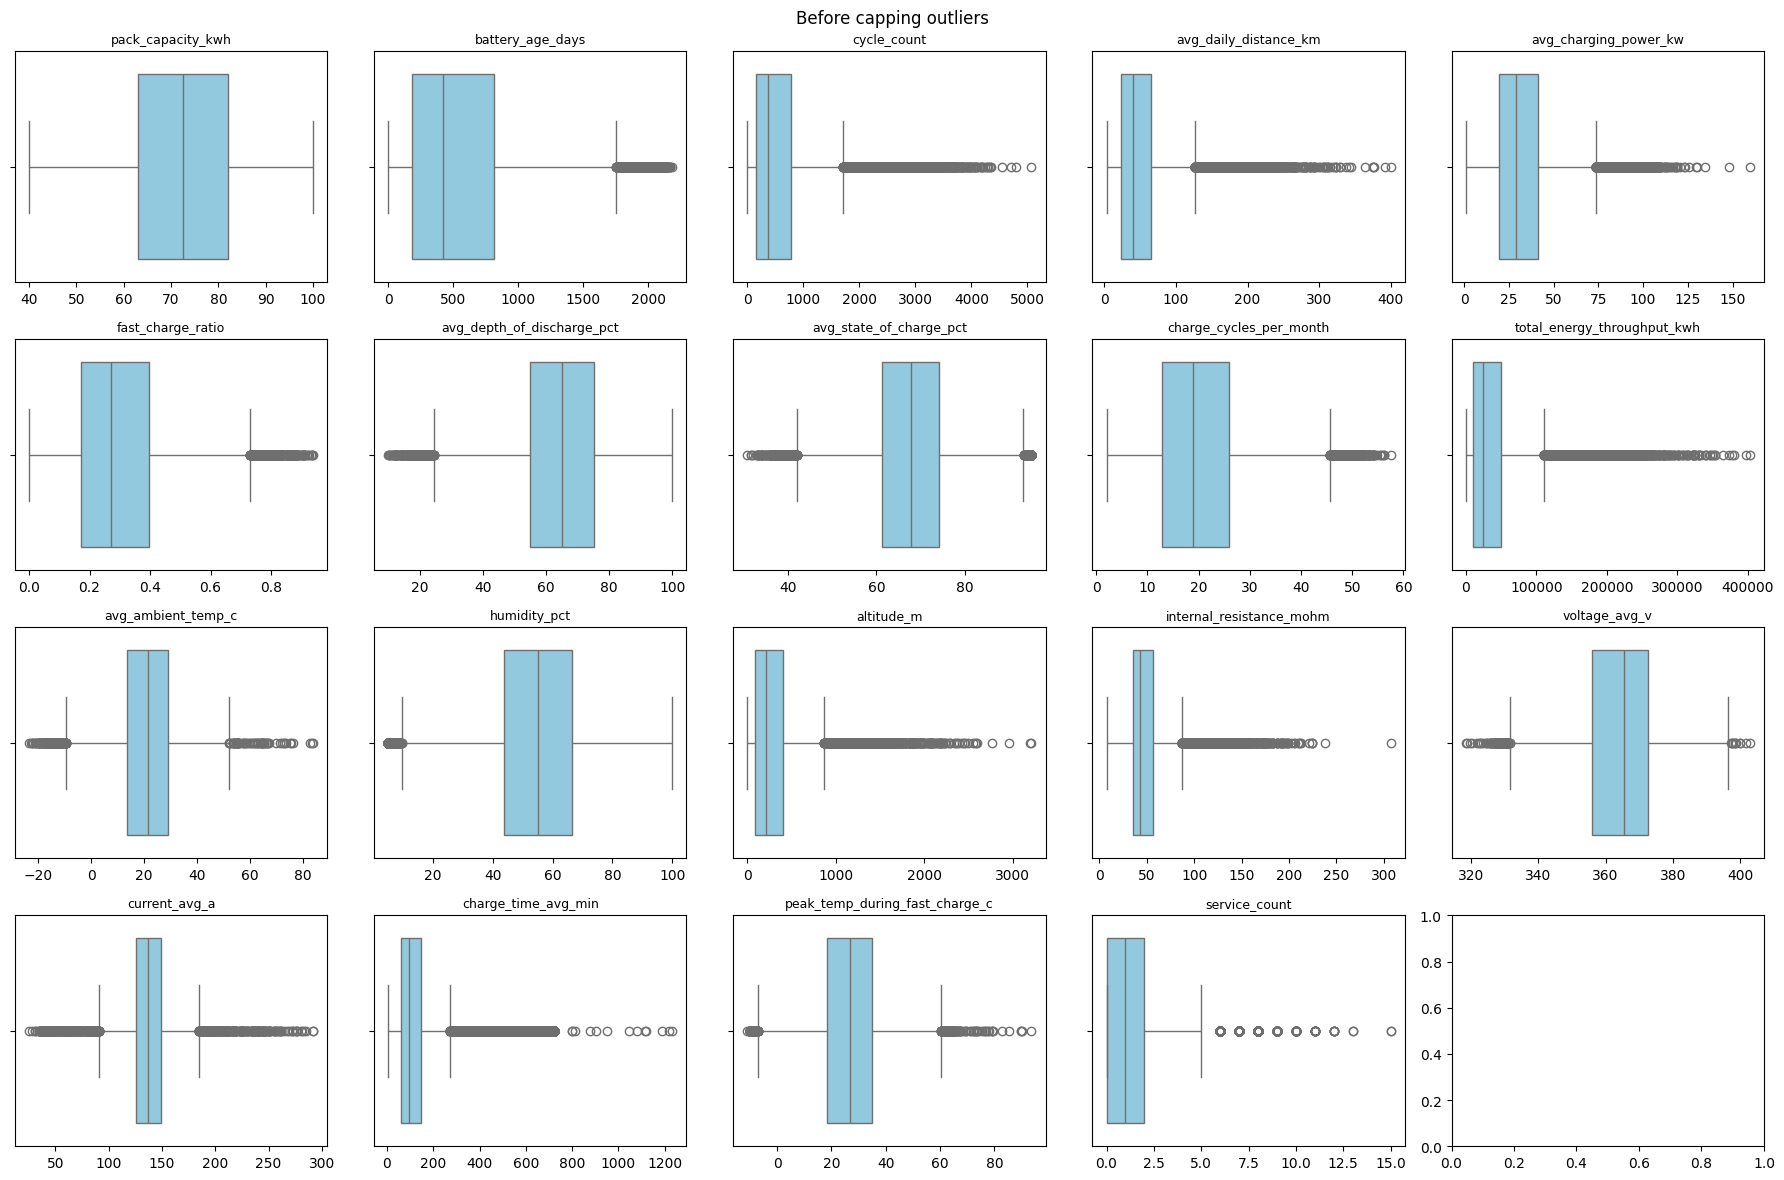

In [25]:
# boxplots before capping
fig, axes = plt.subplots(4, 5, figsize=(18, 12))
for ax, col in zip(axes.flatten(), outlier_cols):
    sns.boxplot(x=df[col], ax=ax, color="skyblue")
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("")
plt.suptitle("Before capping outliers")
plt.tight_layout()
plt.show()

In [26]:
# count outliers and cap them
for col in outlier_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col:32s} outliers = {outliers}")
    df[col] = df[col].clip(lower, upper)

pack_capacity_kwh                outliers = 0
battery_age_days                 outliers = 1015
cycle_count                      outliers = 2757
avg_daily_distance_km            outliers = 2499
avg_charging_power_kw            outliers = 1436
fast_charge_ratio                outliers = 552
avg_depth_of_discharge_pct       outliers = 265
avg_state_of_charge_pct          outliers = 506
charge_cycles_per_month          outliers = 660
total_energy_throughput_kwh      outliers = 3107
avg_ambient_temp_c               outliers = 410
humidity_pct                     outliers = 283
altitude_m                       outliers = 2641
internal_resistance_mohm         outliers = 2940
voltage_avg_v                    outliers = 161
current_avg_a                    outliers = 894
charge_time_avg_min              outliers = 3585
peak_temp_during_fast_charge_c   outliers = 322
service_count                    outliers = 1520


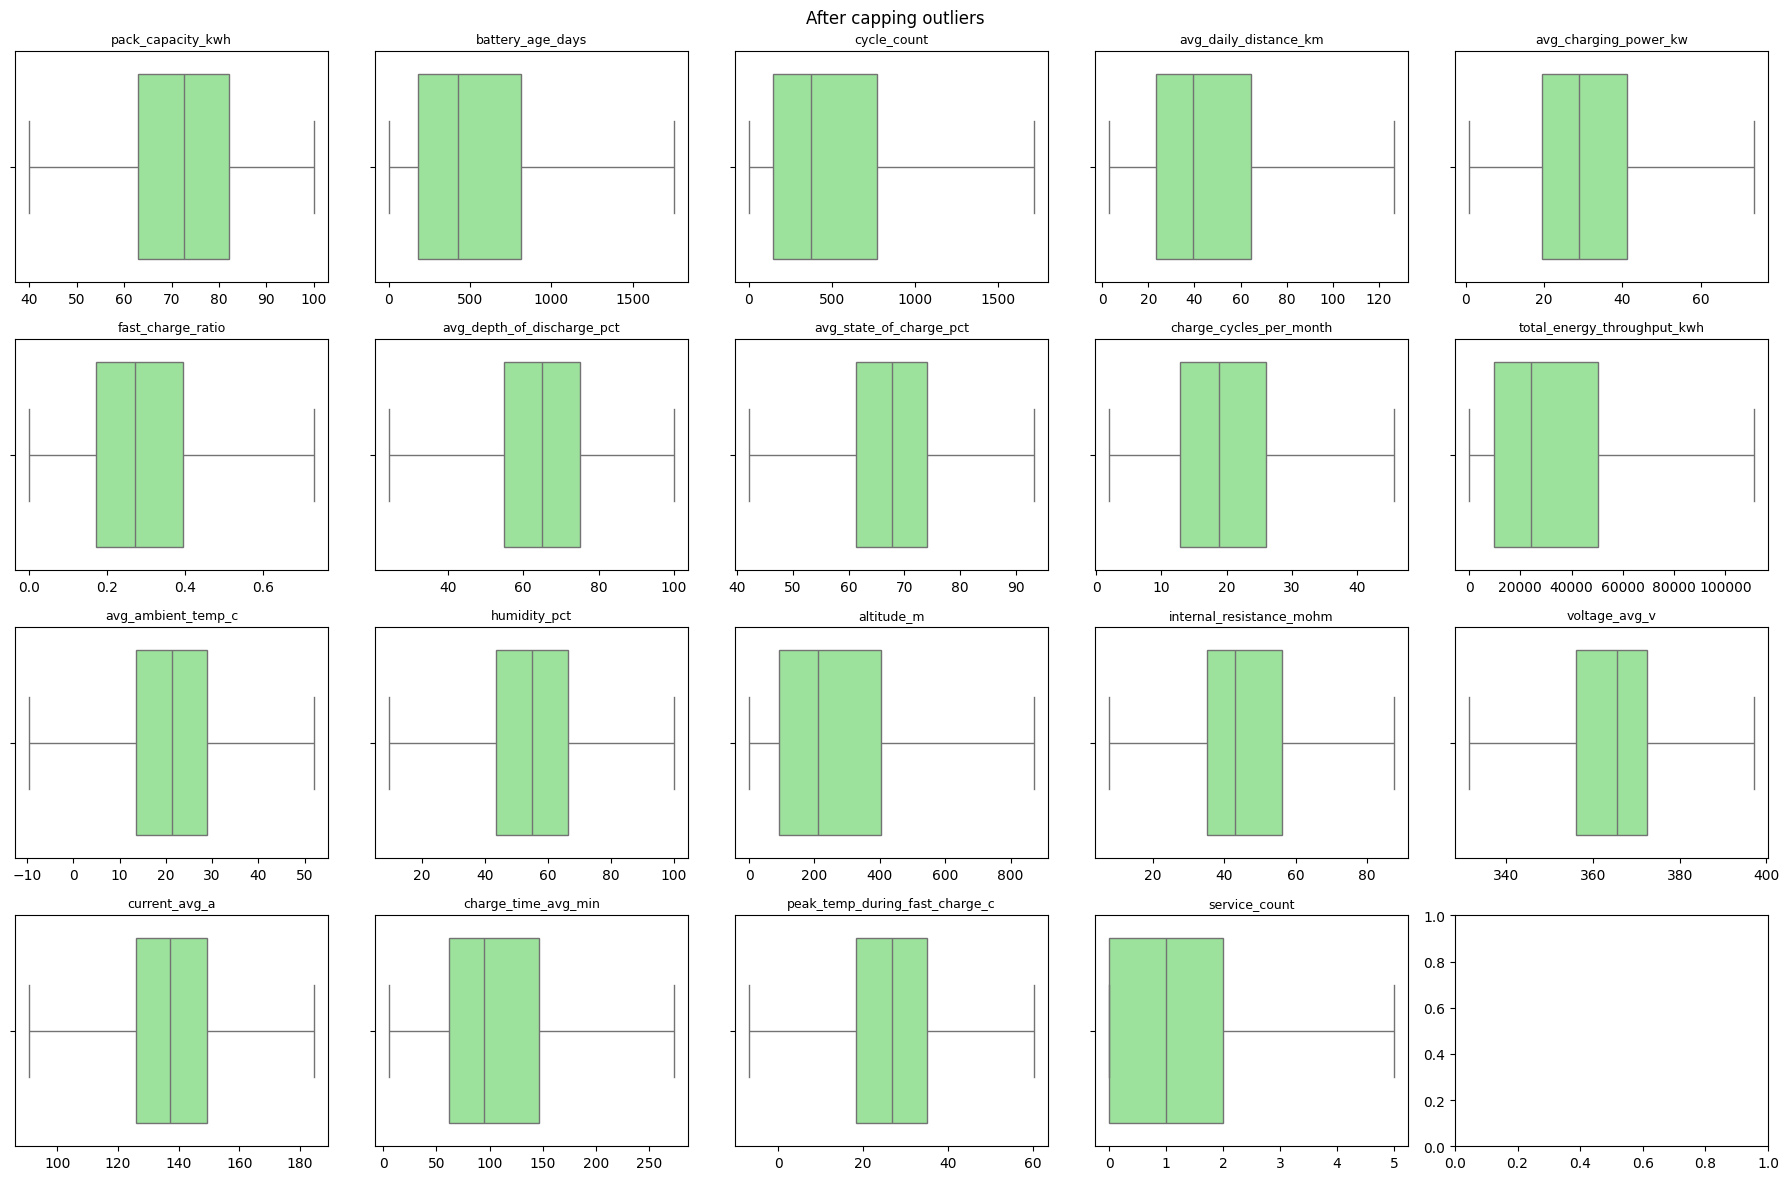

In [27]:
# boxplots after capping
fig, axes = plt.subplots(4, 5, figsize=(18, 12))
for ax, col in zip(axes.flatten(), outlier_cols):
    sns.boxplot(x=df[col], ax=ax, color="lightgreen")
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("")
plt.suptitle("After capping outliers")
plt.tight_layout()
plt.show()

### EDA (Exploratory Data Analysis)

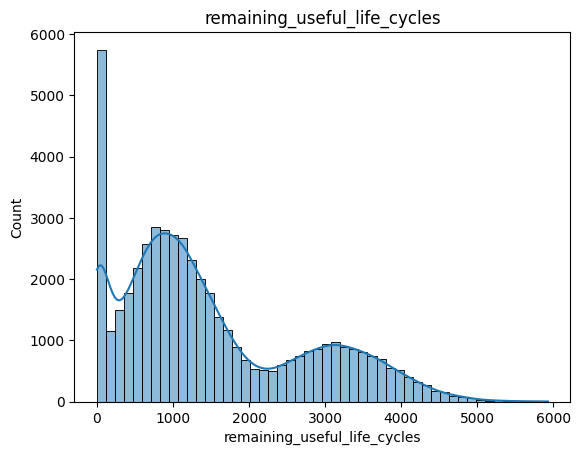

In [28]:
sns.histplot(df["remaining_useful_life_cycles"], bins=50, kde=True)
plt.title("remaining_useful_life_cycles")
plt.show()

In [29]:
co = df.corr(numeric_only=True)   # correlation between numeric columns

In [30]:
co["remaining_useful_life_cycles"].sort_values(ascending=False)   # correlation of every column with the target

remaining_useful_life_cycles      1.000000
avg_ambient_temp_c                0.026267
peak_temp_during_fast_charge_c    0.022533
avg_state_of_charge_pct           0.022473
recall_flag                       0.004755
altitude_m                        0.004755
humidity_pct                     -0.000744
voltage_avg_v                    -0.004941
current_avg_a                    -0.006510
avg_charging_power_kw            -0.010486
fast_charge_ratio                -0.012196
charge_time_avg_min              -0.012693
avg_depth_of_discharge_pct       -0.024058
pack_capacity_kwh                -0.070166
avg_daily_distance_km            -0.116135
charge_cycles_per_month          -0.167125
service_count                    -0.228401
battery_age_days                 -0.315619
total_energy_throughput_kwh      -0.373193
cycle_count                      -0.377948
internal_resistance_mohm         -0.588522
Name: remaining_useful_life_cycles, dtype: float64

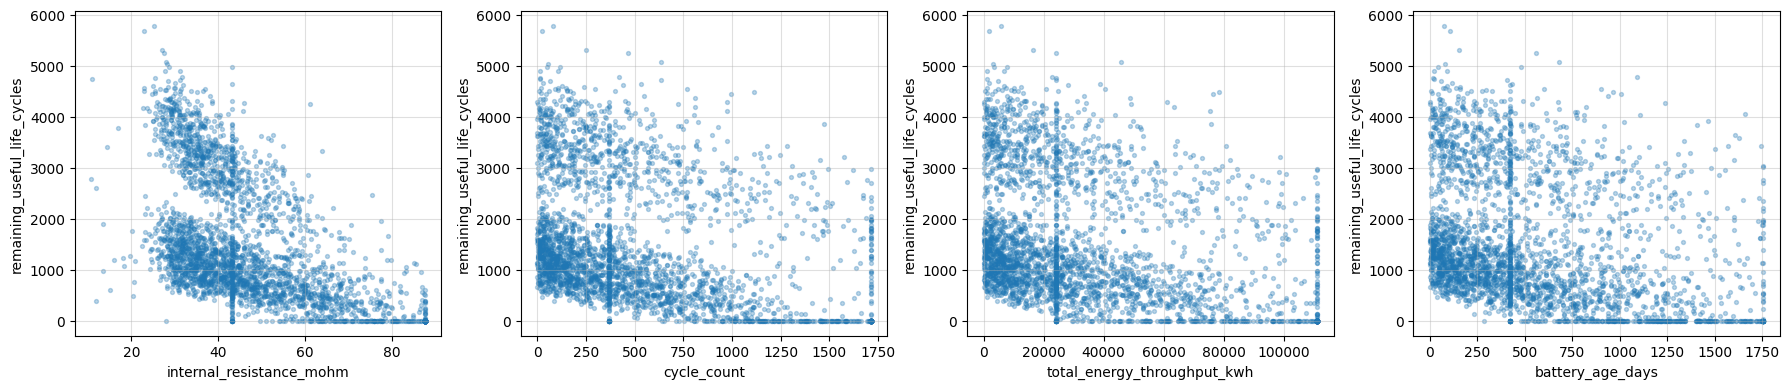

In [31]:
# scatter plot of the 4 most correlated columns with the target
features = co["remaining_useful_life_cycles"].drop("remaining_useful_life_cycles").abs().sort_values(ascending=False).head(4).index
sample = df.sample(3000, random_state=42)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, features):
    ax.scatter(sample[col], sample["remaining_useful_life_cycles"], alpha=0.3, s=8)
    ax.set_xlabel(col)
    ax.set_ylabel("remaining_useful_life_cycles")
    ax.grid(alpha=0.4)
plt.tight_layout()
plt.show()

### Encode text columns

In [33]:
cat_col

Index(['chemistry', 'manufacturer', 'vehicle_model', 'climate_zone',
       'bms_firmware_version'],
      dtype='object')

In [35]:
encoders = {}
for col in cat_col:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    encoders[col] = le   # keep the encoder so new data can be encoded the same way

In [36]:
df.head()

,chemistry,manufacturer,vehicle_model,pack_capacity_kwh,battery_age_days,cycle_count,climate_zone,avg_daily_distance_km,avg_charging_power_kw,fast_charge_ratio,...,altitude_m,internal_resistance_mohm,voltage_avg_v,current_avg_a,charge_time_avg_min,peak_temp_during_fast_charge_c,service_count,bms_firmware_version,recall_flag,remaining_useful_life_cycles
0,1,6,1,48.5,693.0,991.0,0,120.3,28.8,0.345,...,390.0,87.52,365.6,146.4,40.1,-1.3,4.0,0,0.0,0
1,0,7,5,61.5,662.0,1535.0,0,93.4,73.5,0.569,...,871.0,49.95,357.3,176.0,38.0,5.3,0.0,3,0.0,1739
2,0,3,7,73.1,424.0,407.0,0,45.0,73.5,0.641,...,249.0,37.90,375.4,156.8,41.7,21.3,0.0,2,0.0,3248
3,3,0,7,75.6,33.0,29.0,0,42.4,73.5,0.596,...,3.0,43.08,361.7,150.3,18.2,20.8,0.0,4,0.0,1375
4,2,7,2,92.7,520.0,324.0,1,23.4,36.3,0.550,...,206.0,68.34,374.0,159.5,79.2,40.1,0.0,0,0.0,715


### Splitting into train and test

In [37]:
x = df.drop(["remaining_useful_life_cycles"], axis=1)
y = df["remaining_useful_life_cycles"]


In [38]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
print("Training rows :", len(x_train))
print("Test rows :", len(x_test))

Training rows : 40000
Test rows : 10000


### Scaling

In [39]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

### Train the models

In [41]:
results = []   # we store the score of every model here
models = {}    # and the trained models here

#### 1. Linear Regression

In [42]:
lr_model = LinearRegression()
lr_model.fit(x_train, y_train)
y_pred_lr = lr_model.predict(x_test)

mae = mean_absolute_error(y_test, y_pred_lr)
mse = mean_squared_error(y_test, y_pred_lr)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_lr)
train_r2 = lr_model.score(x_train, y_train)

print(f"MAE = {mae:.2f}  MSE = {mse:.2f}  RMSE = {rmse:.2f}  R2 = {r2:.3f}")
print(f"Train R2 = {train_r2:.3f}  Test R2 = {r2:.3f}")

results.append(["Linear Regression", train_r2, r2, mae, rmse])
models["Linear Regression"] = lr_model

MAE = 572.67  MSE = 546977.89  RMSE = 739.58  R2 = 0.638
Train R2 = 0.634  Test R2 = 0.638


#### 2. Decision Tree

In [43]:
dt_model = DecisionTreeRegressor(max_depth=12, random_state=42)
dt_model.fit(x_train, y_train)
y_pred_dt = dt_model.predict(x_test)

mae = mean_absolute_error(y_test, y_pred_dt)
mse = mean_squared_error(y_test, y_pred_dt)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_dt)
train_r2 = dt_model.score(x_train, y_train)

print(f"MAE = {mae:.2f}  MSE = {mse:.2f}  RMSE = {rmse:.2f}  R2 = {r2:.3f}")
print(f"Train R2 = {train_r2:.3f}  Test R2 = {r2:.3f}")

results.append(["Decision Tree", train_r2, r2, mae, rmse])
models["Decision Tree"] = dt_model

MAE = 331.87  MSE = 242541.66  RMSE = 492.49  R2 = 0.839
Train R2 = 0.911  Test R2 = 0.839


#### 3. Random Forest

In [44]:
rf_model = RandomForestRegressor(n_estimators=100, max_depth=15, n_jobs=-1, random_state=42)
rf_model.fit(x_train, y_train)
y_pred_rf = rf_model.predict(x_test)

mae = mean_absolute_error(y_test, y_pred_rf)
mse = mean_squared_error(y_test, y_pred_rf)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_rf)
train_r2 = rf_model.score(x_train, y_train)

print(f"MAE = {mae:.2f}  MSE = {mse:.2f}  RMSE = {rmse:.2f}  R2 = {r2:.3f}")
print(f"Train R2 = {train_r2:.3f}  Test R2 = {r2:.3f}")

results.append(["Random Forest", train_r2, r2, mae, rmse])
models["Random Forest"] = rf_model

MAE = 300.40  MSE = 187632.13  RMSE = 433.17  R2 = 0.876
Train R2 = 0.945  Test R2 = 0.876


#### 4. Gradient Boosting

In [45]:
gb_model = GradientBoostingRegressor(n_estimators=200, random_state=42)
gb_model.fit(x_train, y_train)
y_pred_gb = gb_model.predict(x_test)

mae = mean_absolute_error(y_test, y_pred_gb)
mse = mean_squared_error(y_test, y_pred_gb)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_gb)
train_r2 = gb_model.score(x_train, y_train)

print(f"MAE = {mae:.2f}  MSE = {mse:.2f}  RMSE = {rmse:.2f}  R2 = {r2:.3f}")
print(f"Train R2 = {train_r2:.3f}  Test R2 = {r2:.3f}")

results.append(["Gradient Boosting", train_r2, r2, mae, rmse])
models["Gradient Boosting"] = gb_model

MAE = 310.48  MSE = 196724.53  RMSE = 443.54  R2 = 0.870
Train R2 = 0.873  Test R2 = 0.870


### Compare the models

In [46]:
compare = pd.DataFrame(results, columns=["model", "train_r2", "test_r2", "mae", "rmse"])
compare = compare.sort_values("test_r2", ascending=False).round(3)
compare

,model,train_r2,test_r2,mae,rmse
2,Random Forest,0.945,0.876,300.401,433.165
3,Gradient Boosting,0.873,0.870,310.479,443.536
1,Decision Tree,0.911,0.839,331.871,492.485
0,Linear Regression,0.634,0.638,572.666,739.580


In [47]:
best_name = compare.iloc[0]["model"]
best_model = models[best_name]
print("Best model :", best_name)

Best model : Random Forest


### Save the best model

In [48]:
saved = {
    "model": models[" Random Forest"],
    "scaler": scaler,
    "encoders": encoders,
    "columns": list(x.columns),
}
joblib.dump(saved, "../models/rul_model.pkl", compress=3)
print("Saved : models/rul_model.pkl")

KeyError: ' Random Forest'